# Week 2 — Day 3: Probability Calibration and Thresholds

## Goals
- Understand probability calibration
- Evaluate probabilities with the Brier score
- Plot a reliability diagram
- Understand the default 0.5 classification threshold
- Compare thresholds using validation data
- Evaluate the selected threshold on the test period
- Understand the trade-off between precision and recall

In [1]:
#Import Statements
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.calibration import calibration_curve

In [2]:
#Load the raw AAPL data
data = pd.read_csv(
    "../data/raw/AAPL_daily_raw.csv",
    index_col="Date",
    parse_dates=True
)

# Normalize potentially timezone-aware dates.
data.index = pd.to_datetime(
    data.index, utc=True
).tz_localize(None)

data = data.sort_index()

print("Shape:", data.shape)
print("Date range:", data.index.min(), "to", data.index.max())

data.head()

Shape: (2766, 9)
Date range: 2015-01-02 05:00:00 to 2025-12-31 05:00:00


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,daily_return
Date,,,,,,,,,
2015-01-02 05:00:00,27.847500,27.860001,26.837500,27.332500,24.171755,212818400,0.0,0.0,NaN
2015-01-05 05:00:00,27.072500,27.162500,26.352501,26.562500,23.490799,257142000,0.0,0.0,-0.028172
2015-01-06 05:00:00,26.635000,26.857500,26.157499,26.565001,23.493013,263188400,0.0,0.0,0.000094
2015-01-07 05:00:00,26.799999,27.049999,26.674999,26.937500,23.822430,160423600,0.0,0.0,0.014022
2015-01-08 05:00:00,27.307501,28.037500,27.174999,27.972500,24.737757,237458000,0.0,0.0,0.038423


In [3]:
#Returns, Trends and Momentum Features
data["daily_return"] = data["Adj Close"].pct_change()

data["SMA_20"] = data["Adj Close"].rolling(20).mean()
data["SMA_50"] = data["Adj Close"].rolling(50).mean()
data["SMA_200"] = data["Adj Close"].rolling(200).mean()

data["EMA_12"] = (
    data["Adj Close"].ewm(span=12, adjust=False).mean()
)

data["EMA_26"] = (
    data["Adj Close"].ewm(span=26, adjust=False).mean()
)

data["price_to_SMA20"] = (
    data["Adj Close"] / data["SMA_20"] - 1
)

data["SMA20_to_SMA50"] = (
    data["SMA_20"] / data["SMA_50"] - 1
)

data["momentum_10d"] = (
    data["Adj Close"] / data["Adj Close"].shift(10) - 1
)

data["rolling_20d_volatility"] = (
    data["daily_return"].rolling(20).std()
)

data["return_lag_1"] = data["daily_return"].shift(1)
data["return_lag_5"] = data["daily_return"].shift(5)

In [4]:
#RSI AND MACD Features
delta = data["Adj Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.ewm(alpha=1 / 14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / 14, adjust=False).mean()

rs = avg_gain / avg_loss.replace(0, np.nan)

data["RSI_14"] = 100 - (100 / (1 + rs))

data.loc[
    (avg_loss == 0) & (avg_gain > 0),
    "RSI_14"
] = 100

data["MACD"] = data["EMA_12"] - data["EMA_26"]

data["MACD_signal"] = (
    data["MACD"].ewm(span=9, adjust=False).mean()
)

data["MACD_hist"] = data["MACD"] - data["MACD_signal"]

In [5]:
#Bollinger Bands and Volume Features
rolling_std_20 = data["Adj Close"].rolling(20).std()

data["BB_upper"] = data["SMA_20"] + 2 * rolling_std_20
data["BB_lower"] = data["SMA_20"] - 2 * rolling_std_20

band_width = data["BB_upper"] - data["BB_lower"]

data["BB_percent_b"] = (
    (data["Adj Close"] - data["BB_lower"]) / band_width
)

data["volume_change"] = data["Volume"].pct_change()

data["volume_SMA20"] = data["Volume"].rolling(20).mean()

data["relative_volume"] = (
    data["Volume"] / data["volume_SMA20"]
)

data = data.replace([np.inf, -np.inf], np.nan)

In [6]:
#Create the target variable for the next day's return
data["future_return_1d"] = (
    data["Adj Close"].shift(-1) / data["Adj Close"] - 1
)

data["target_up"] = np.nan

valid_target = data["future_return_1d"].notna()

data.loc[valid_target, "target_up"] = (
    data.loc[valid_target, "future_return_1d"] > 0
).astype(int)

In [7]:
#Define the feature columns and create the model dataset
feature_columns = [
    "daily_return",
    "return_lag_1",
    "return_lag_5",
    "rolling_20d_volatility",
    "SMA_20",
    "SMA_50",
    "SMA_200",
    "EMA_12",
    "EMA_26",
    "price_to_SMA20",
    "SMA20_to_SMA50",
    "momentum_10d",
    "RSI_14",
    "MACD",
    "MACD_signal",
    "MACD_hist",
    "BB_percent_b",
    "volume_change",
    "relative_volume"
]

model_data = data[
    feature_columns + ["future_return_1d", "target_up"]
].dropna().copy()

model_data["target_up"] = model_data["target_up"].astype(int)
model_data = model_data.sort_index()

print("Model dataset shape:", model_data.shape)
model_data.head()

Model dataset shape: (2566, 21)


,daily_return,return_lag_1,return_lag_5,rolling_20d_volatility,SMA_20,SMA_50,SMA_200,EMA_12,EMA_26,price_to_SMA20,...,momentum_10d,RSI_14,MACD,MACD_signal,MACD_hist,BB_percent_b,volume_change,relative_volume,future_return_1d,target_up
Date,,,,,,,,,,,,,,,,,,,,,
2015-10-16 04:00:00,-0.007330,0.014971,0.023927,0.013303,25.025021,25.154457,27.011853,24.921899,25.058386,-0.006526,...,0.005980,47.284859,-0.136487,-0.159463,0.022976,0.403032,0.041385,0.782110,0.006214,1
2015-10-19 04:00:00,0.006214,-0.007330,-0.004638,0.012851,24.986064,25.137486,27.016075,24.936404,25.055260,0.001205,...,0.008576,49.316799,-0.118856,-0.151341,0.032486,0.519810,-0.241468,0.605608,0.018258,1
2015-10-20 04:00:00,0.018258,0.006214,0.001703,0.013110,24.990206,25.110842,27.025986,25.018947,25.086199,0.019317,...,0.022101,54.857082,-0.067252,-0.134524,0.067272,0.813324,0.645468,0.997908,-0.000088,0
2015-10-21 04:00:00,-0.000088,0.018258,-0.014134,0.012978,24.983937,25.112051,27.035874,25.088446,25.114680,0.019483,...,0.026900,54.825440,-0.026233,-0.112866,0.086632,0.823909,-0.146476,0.846530,0.015295,1
2015-10-22 04:00:00,0.015295,-0.000088,0.014971,0.013372,24.989534,25.113215,27.046064,25.207189,25.169909,0.034844,...,0.054795,59.231391,0.037280,-0.082836,0.120117,1.060613,-0.003376,0.851054,0.030996,1


In [8]:
#Checking the feature does not include the target variable or future return
assert "future_return_1d" not in feature_columns
assert "target_up" not in feature_columns

print("Target and features are separated.")

Target and features are separated.


In [11]:
#Split the data into train, validation, and test sets
n = len(model_data)

train_end = int(n * 0.70)
validation_end = int(n * 0.85)

train = model_data.iloc[:train_end].copy()
validation = model_data.iloc[train_end:validation_end].copy()
test = model_data.iloc[validation_end:].copy()

X_train = train[feature_columns]
X_validation = validation[feature_columns]
X_test = test[feature_columns]

y_train = train["target_up"]
y_validation = validation["target_up"]
y_test = test["target_up"]

print("Train:     ", train.index.min(), "to", train.index.max())
print("Validation:", validation.index.min(), "to", validation.index.max())
print("Test:      ", test.index.min(), "to", test.index.max())

print("\nRows:", len(train), len(validation), len(test))

assert train.index.max() < validation.index.min()
assert validation.index.max() < test.index.min()
assert y_train.nunique() == 2
assert y_validation.nunique() == 2
assert y_test.nunique() == 2

Train:      2015-10-16 04:00:00 to 2022-12-02 05:00:00
Validation: 2022-12-05 05:00:00 to 2024-06-17 04:00:00
Test:       2024-06-18 04:00:00 to 2025-12-30 05:00:00

Rows: 1796 385 385


In [12]:
#Train standard Logistic Regression on the training period
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model trained on the training period.")

Model trained on the training period.


In [13]:
#Get the predicted probabilities for the UP class on the validation and test sets
classes = list(model.named_steps["classifier"].classes_)
up_index = classes.index(1)

probability_up_validation = (
    model.predict_proba(X_validation)[:, up_index]
)

probability_up_test = (
    model.predict_proba(X_test)[:, up_index]
)

print("First 10 validation UP probabilities:")
print(probability_up_validation[:10])

First 10 validation UP probabilities:
[0.58803748 0.59064471 0.53544582 0.47663395 0.48016828 0.47784599
 0.4814634  0.55541708 0.58811857 0.55280622]


In [14]:
#Calculate the Brier score for the validation and test sets
validation_brier = brier_score_loss(
    y_validation,
    probability_up_validation
)

test_brier = brier_score_loss(
    y_test,
    probability_up_test
)

print(f"Validation Brier score: {validation_brier:.4f}")
print(f"Test Brier score:       {test_brier:.4f}")

Validation Brier score: 0.2513
Test Brier score:       0.2562


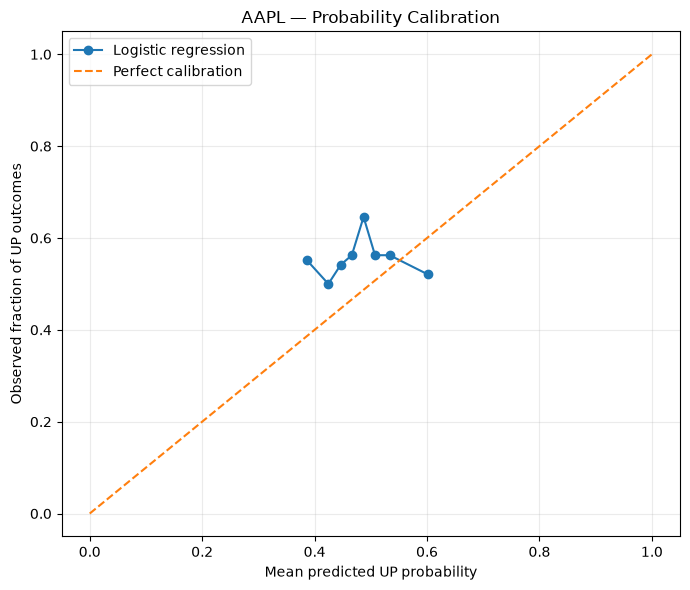

In [15]:
#Plot the calibration curve for the test set
observed_fraction, mean_predicted_probability = calibration_curve(
    y_test,
    probability_up_test,
    n_bins=8,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted_probability,
    observed_fraction,
    marker="o",
    label="Logistic regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.title("AAPL — Probability Calibration")
plt.xlabel("Mean predicted UP probability")
plt.ylabel("Observed fraction of UP outcomes")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()